# Hwang et al. 2022 — Pancreatic Ductal Adenocarcinoma (snRNA-seq, 10x)
## Step 01 — Preprocessing & Gate 1 (integration / continuity)

Fully-autonomous CCCA re-analysis. Malignant cells only. Every tunable choice is **derived from this
dataset** (02_train C1–C4), not inherited from the Puram2017 skeleton. Gate 1 is judged **visually on the
regenerated embedding** across a Harmony integration-strength (`theta`) x `n_pcs` sweep with a
per-neighbourhood **iLISI** metric — never a single scalar (03_eval fork 1).

In [1]:
import os, sys, glob, time, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'   # scFates PPT -> rpy2 -> r-mgcv
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import scipy.sparse as sp
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

### Paths
`cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>` — two levels below Puram, so the
root is six `..` up. Notebooks run in place.

In [2]:
name = os.path.basename(os.getcwd())                    # 'Hwang2022_Pancreas-1'
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # 'Pancreas'
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
dataname = name.replace('-1','')                        # raw folder has no -1 suffix
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + dataname)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Hwang2022_Pancreas-1 | category: Pancreas


### Load malignant cells
This dataset ships **three leaf matrix dirs** (`Group1/2/3`); following the `merge.py` `os.walk` leaf
convention we load each with `load_CCCA_adata` and concat. Expression is **TP10K** (pass-through +
`log1p`). Analyze **Malignant** cells only.

In [3]:
leaves = sorted(dp for dp,sd,_ in os.walk(pth_in) if len(sd)==0)
print('leaf dirs:', [os.path.basename(l) for l in leaves])
import anndata as ad
adata = ad.concat({l: load_CCCA_adata(l, verbose=False) for l in leaves},
                  join='outer', merge='same', label='source')
adata.obs_names_make_unique()
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of TP10K)' % adata.X.max())

leaf dirs: ['Group1', 'Group2', 'Group3']
malignant: (64538, 22164) | samples: 43
expression: X max 5.88 (log1p of TP10K)


### Sample threshold — derived by gap-finding (C1: derived, not inherited)
Sort per-sample malignant counts, find the largest consecutive ratio gap, set the threshold to the
geometric mean across it. **C3 note:** this PDAC distribution is smooth — the only clear gap sits far
in the tail (24 -> 9 cells), so the rule keeps essentially all samples; a handful of <14-cell samples
are dropped. Tiny detached specks are handled by island removal below, not by the threshold.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1]/vals[1:]
gap = int(np.argmax(ratios)); thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', vals.astype(int).tolist())
print(f'largest gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells; dropped:', sorted(n.index[n<thresh].tolist()))

sorted per-sample counts: [7167, 5790, 4865, 4766, 4349, 3808, 3652, 3557, 3284, 3271, 3114, 2875, 1963, 1536, 1501, 1426, 1304, 1068, 1019, 817, 609, 485, 478, 446, 342, 182, 175, 155, 100, 85, 65, 46, 44, 39, 35, 33, 32, 24, 9, 9, 6, 4, 3]
largest gap: 24 -> 9 (ratio 2.67)
derived threshold (geometric mean across gap) = 14
kept 38/43 samples -> 64507 cells; dropped: ['T10', 'T13', 'T2', 'T21', 'T9']


### Genes, overdispersion, PCA

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()), '| genes retained:', adata.shape[1])
sc.pp.pca(adata, n_comps=50, use_highly_variable=True)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1664 over-dispersed features (0:00:06) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1664 | genes retained: 19457


### Gate 1 sweep — Harmony `theta` x `n_pcs`, per-neighbourhood iLISI
iLISI = inverse-Simpson diversity of `sample` labels within each cell's kNN (k=90); **higher = better
sample mixing** (max = n_samples). We sweep `theta in {0,2,5,10,20}` x `n_pcs in {20,40}`. `theta=0`
is raw PCA (no integration). The embedding — not the scalar — makes the call; the scalar only locates
the plateau.

In [6]:
samp = adata.obs['sample'].values; NSAMP = adata.obs['sample'].nunique()
def ilisi(rep, k=90):
    nn = NearestNeighbors(n_neighbors=k).fit(rep).kneighbors(rep, return_distance=False)
    out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(samp[nn[i]], return_counts=True); p = cnt/cnt.sum()
        out[i] = 1.0/np.sum(p**2)
    return out
adata.obsm['X_theta0'] = adata.obsm['X_pca'].copy()
for th in [2,5,10,20]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    adata.obsm[f'X_theta{th}'] = adata.obsm['X_pca_harmony'].copy()
rows = []
for th in [0,2,5,10,20]:
    for npc in [20,40]:
        il = ilisi(adata.obsm[f'X_theta{th}'][:,:npc])
        rows.append((th,npc,np.median(il)))
        print(f'theta={th:2d} n_pcs={npc:2d} | iLISI median={np.median(il):.1f}  (max {NSAMP})')
sweep = pd.DataFrame(rows, columns=['theta','n_pcs','iLISI_median'])

theta= 0 n_pcs=20 | iLISI median=1.0  (max 38)
theta= 0 n_pcs=40 | iLISI median=1.0  (max 38)
theta= 2 n_pcs=20 | iLISI median=8.7  (max 38)
theta= 2 n_pcs=40 | iLISI median=7.7  (max 38)
theta= 5 n_pcs=20 | iLISI median=9.1  (max 38)
theta= 5 n_pcs=40 | iLISI median=8.1  (max 38)
theta=10 n_pcs=20 | iLISI median=9.3  (max 38)
theta=10 n_pcs=40 | iLISI median=8.2  (max 38)
theta=20 n_pcs=20 | iLISI median=6.7  (max 38)
theta=20 n_pcs=40 | iLISI median=5.8  (max 38)


**Read:** raw PCA is fully sample-segregated (iLISI 1.0). Mixing rises to a plateau at
`theta=10, n_pcs=20` (median ~9/38) then **degrades at `theta=20`** (iLISI falls, residual sample
clumps re-appear = over-integration). `n_pcs=20` mixes slightly better than 40 and matches the
Kürten/Puram 10x precedent scale. **Selected: `theta=10, n_pcs=20, spread=1.3`.**

In [7]:
THETA, NPC, SPREAD = 10, 20, 1.3
adata.obsm['X_pca_harmony'] = adata.obsm[f'X_theta{THETA}']
sc.pp.neighbors(adata, n_pcs=NPC, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=SPREAD, random_state=SEED)
adata.obs['iLISI'] = ilisi(adata.obsm['X_pca_harmony'][:,:NPC])
print('selected theta=%d n_pcs=%d spread=%.1f | iLISI median=%.1f of %d' % (THETA,NPC,SPREAD,np.median(adata.obs['iLISI']),NSAMP))

selected theta=10 n_pcs=20 spread=1.3 | iLISI median=9.3 of 38


### Integration-strength sweep figure (visual Gate-1 evidence)

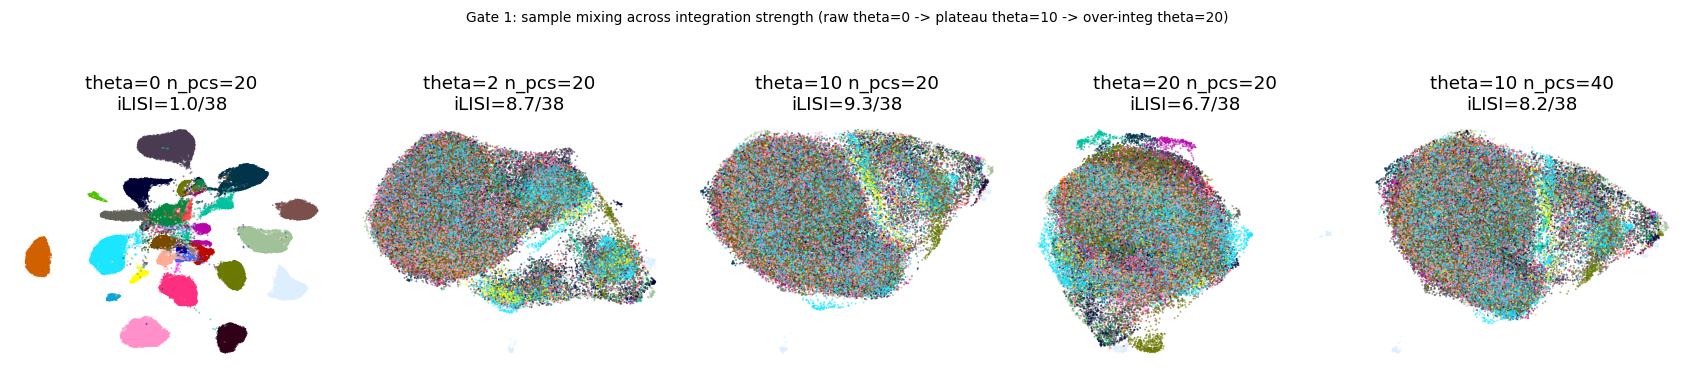

In [8]:
cfgs = [(0,20),(2,20),(10,20),(20,20),(10,40)]
reps = {}
for th,npc in cfgs:
    sc.pp.neighbors(adata, n_pcs=npc, use_rep=f'X_theta{th}', n_neighbors=30, random_state=SEED, key_added='swp')
    sc.tl.umap(adata, spread=SPREAD, random_state=SEED, neighbors_key='swp')
    reps[(th,npc)] = adata.obsm['X_umap'].copy()
fig, axes = plt.subplots(1, len(cfgs), figsize=(3.1*len(cfgs), 3.2))
for ax,(th,npc) in zip(axes, cfgs):
    adata.obsm['X_umap'] = reps[(th,npc)]
    med = np.median(ilisi(adata.obsm[f'X_theta{th}'][:,:npc]))
    sc.pl.umap(adata, color='sample', size=6, alpha=.6, frameon=False, show=False, ax=ax, legend_loc=None,
               title=f'theta={th} n_pcs={npc}\niLISI={med:.1f}/{NSAMP}')
fig.suptitle('Gate 1: sample mixing across integration strength (raw theta=0 -> plateau theta=10 -> over-integ theta=20)', y=1.05, size=9)
fig.tight_layout(); plt.show()
adata.obsm['X_umap'] = reps[(THETA,NPC)]

### Island removal — radius graph, keep largest connected component (C1: automated)
Build a UMAP radius graph at 6x the median nearest-neighbour distance; keep the largest connected
component. Strictly conservative — strips only disconnected specks.

In [9]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached specks')
adata = adata[lab==main].copy(); print('after island removal:', adata.shape[0])

removed 106 cells in 12 detached specks
after island removal: 64401


### Sub-region biology BEFORE the GO (03_eval lobe-identity fork)
A manifold resolves into sub-regions; settle each one's biology (signatures + cell cycle) before
certifying Gate 1, and scope the trajectory only if a sub-region fails to reproduce the reference
relationships. Score the three developmental modules with the union control pool, graph-smooth for
geography, and split into density lobes.

In [10]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.dropna().drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,lab2 in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab2, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab2}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = S[:,j]
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED, flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
gb = adata.obs.groupby('lobe', observed=True)
summ = gb[['Gast_sm','pSom_sm','Crest_sm']].mean(); summ['cycling_frac']=gb['cycling'].mean(); summ['n']=gb.size()
print(summ.round(4).to_string())
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  spatial {a} vs {b}: r={np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.3f}')

Gast: 77/81 genes present
pSom: 92/98 genes present
Crest: 101/104 genes present
      Gast_sm  pSom_sm  Crest_sm  cycling_frac      n
lobe                                                 
0     -0.0020  -0.0023    0.0003        0.0672  30183
1     -0.0030  -0.0036    0.0054        0.0613  23733
2     -0.0155   0.0023    0.0033        0.0627  10485
  spatial Gast_sm vs pSom_sm: r=-0.330
  spatial Crest_sm vs Gast_sm: r=-0.300
  spatial Crest_sm vs pSom_sm: r=-0.387


**Read:** the two density lobes have **near-identical cycling fraction** (~0.06 each) — lobe 1 is
*not* a proliferation compartment (unlike Kürten's cycling lobe), and both hold many samples. The
signature geography is coherent and single-axis: Gast opposes pSom/Crest spatially (Gast<->pSom
r≈-0.33). The two lobes are density **poles of one continuous developmental axis**, so the whole
malignant manifold is kept — no scoping needed.

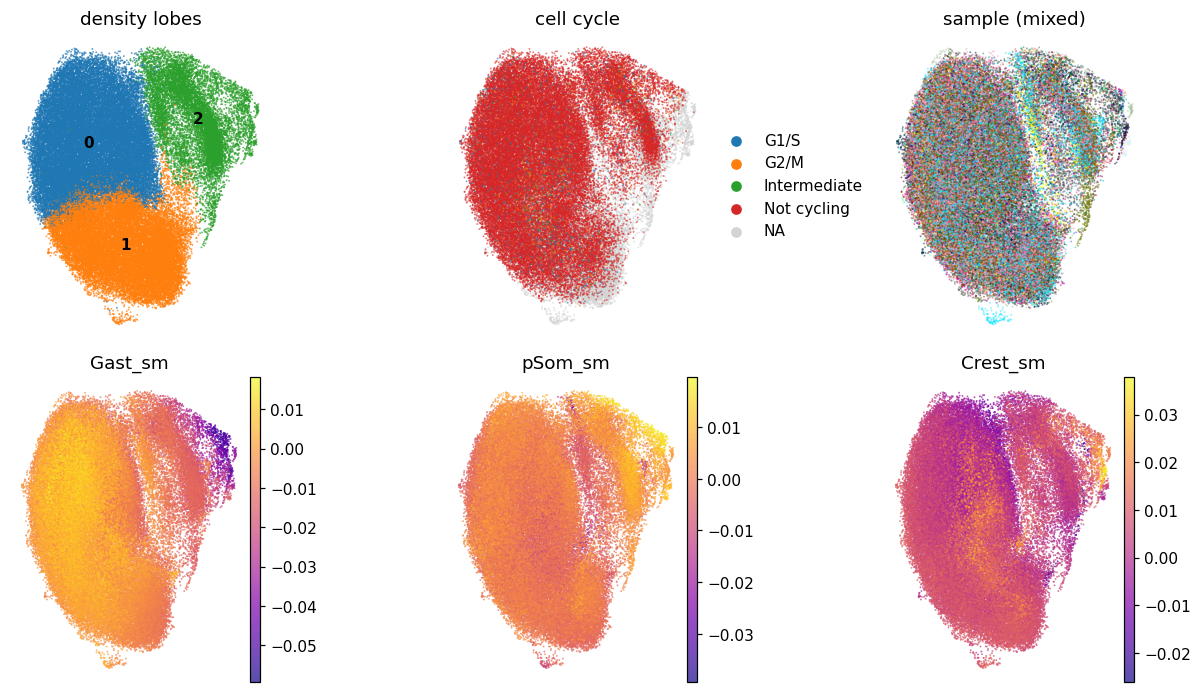

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6.4))
sc.pl.umap(adata, color='lobe', size=6, alpha=.7, frameon=False, show=False, ax=axes[0,0], legend_loc='on data', title='density lobes')
sc.pl.umap(adata, color='cell_cycle_phase', size=6, alpha=.6, frameon=False, show=False, ax=axes[0,1], title='cell cycle')
sc.pl.umap(adata, color='sample', size=6, alpha=.5, frameon=False, show=False, ax=axes[0,2], legend_loc=None, title='sample (mixed)')
for ax,l in zip(axes[1], ['Gast_sm','pSom_sm','Crest_sm']):
    sc.pl.umap(adata, color=l, cmap='plasma', size=6, alpha=.7, frameon=False, show=False, ax=ax, title=l)
fig.tight_layout(); plt.show()

### Gate 1 = GO
Malignant structure is **mixed** (iLISI ~9/38 at theta=10 vs 1.0 raw; degrades at theta=20) **and
continuous** (one connected component after speck removal). The two density lobes are poles of one
developmental axis — not per-sample islands and not a proliferation compartment. **-> GO.**

In [12]:
adata.uns['gate1'] = 'GO'
adata.uns['params'] = dict(theta=THETA, n_pcs=NPC, spread=SPREAD, threshold=int(thresh),
                           overdispersed=int(adata.var.highly_variable.sum()) if 'highly_variable' in adata.var else None)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (64401, 19457)


### Deliverable — `samples.pdf`
House linear-trajectory style: `figsize=(3.5,1.5)`, `size=30`, single sample-coloured manifold panel;
sample intermixing across the manifold is the Gate-1 batch-integration evidence.

saved samples.pdf | cells: 64401 | samples: 38


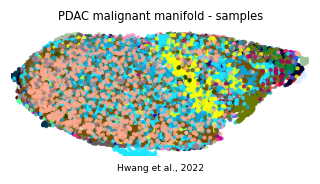

In [13]:
plot = adata.copy(); xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax, legend_loc=None)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('PDAC malignant manifold - samples', size=7.5)
ax.text(.5,-.12,'Hwang et al., 2022', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight'); plt.show()
print('saved samples.pdf | cells:', plot.shape[0], '| samples:', plot.obs['sample'].nunique())